<h1>Project Group 30: Predicting Repeat Purchases with ML</h1>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Notebook 3 of 3</b>: IV. Open-Ended Section and V. Deployment. It reads the prepared training data of Notebook 1 (data/interim) and the final model chosen in Notebook 2 (logs/final_model.json). test.csv is only read in Section V.</p>

</div>

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, log_loss, precision_score, recall_score
from sklearn.model_selection import cross_validate
from tqdm.auto import tqdm

import preprocessing as prep
from preprocessing import TARGET, PLOT_BLUE, PLOT_PURPLE

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 130)

In [2]:
final_model = json.loads(Path("../logs/final_model.json").read_text(encoding="utf-8"))
FINAL_NUMERIC = final_model["numeric"]
FINAL_FLAGS = final_model["flags"]
FINAL_CATEGORICAL = final_model["categorical"]
THRESHOLD = final_model["threshold"]


# the pipeline chosen in Notebook 2, optionally on a different set of variables
def build_final_pipeline(numeric=FINAL_NUMERIC, flags=FINAL_FLAGS, categorical=FINAL_CATEGORICAL):
    model = LogisticRegression(max_iter=5000, **final_model["parameters"])
    return prep.build_pipeline(model, numeric, flags, categorical)


train = prep.load_interim("../data/interim")
development, holdout, inner_folds = prep.split_development_holdout(train)
X_dev, y_dev = development.drop(columns=TARGET), development[TARGET]
X_holdout, y_holdout = holdout.drop(columns=TARGET), holdout[TARGET]

holdout_pipeline = build_final_pipeline().fit(X_dev, y_dev)
holdout_probability = holdout_pipeline.predict_proba(X_holdout)[:, 1]
holdout_prediction = (holdout_probability >= THRESHOLD).astype(int)
print(f"Final model: {final_model['model']}, {final_model['parameters']}, threshold {THRESHOLD}, "
      f"{len(FINAL_NUMERIC + FINAL_FLAGS + FINAL_CATEGORICAL)} variables")
print(f"Holdout F1 {f1_score(y_holdout, holdout_prediction):.4f} "
      f"(Notebook 2: {final_model['holdout_f1']})")

Final model: Logistic regression, {'C': 0.003, 'class_weight': None}, threshold 0.5, 20 variables
Holdout F1 0.7874 (Notebook 2: 0.7874)


<a id="openended"></a>

<h1>IV. Open-Ended Section</h1>

<h2>Objectives for the Section and description of the actions taken</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Section III ends with one number. A sales manager needs more, so this section answers four questions:</p>
<ul>
  <li><b>Objective 1, drivers</b>: which information does the prediction rely on? --> each group of variables is removed from the final set and also used alone (comparison of feature sets, 4 time folds)</li>
  <li><b>Objective 2, errors</b>: for which customers is the prediction unreliable? --> precision, recall and error rate by segment (holdout)</li>
  <li><b>Objective 3, probabilities</b>: are the probabilities right, and can customers be ranked by them? --> log loss before and after calibration, and a contact list from the lowest probabilities (holdout)</li>
  <li><b>Objective 4, tool</b>: why does the model predict what it predicts for one purchase? --> a function that returns the probability and its five main reasons</li>
  <li>Objectives 2 to 4 use the model fitted on the development part, so every result is measured on purchases it has never seen</li>
</ul>

</div>

<h2>Results and discussion of main findings → key takeaways</h2>

<h3>Objective 1: which information drives the prediction?</h3>

In [3]:
# groups of variables for the ablation, restricted to the variables of the final set
final_variables = FINAL_NUMERIC + FINAL_FLAGS + FINAL_CATEGORICAL
variable_groups = {
    "Purchase counts and spend (30 to 365 days)": prep.ROLLING_COUNT + prep.ROLLING_SPEND,
    "Supplied history (gaps, tenure, values)": prep.HISTORY_TIMING + prep.HISTORY_VALUE,
    "Customer history (new)": prep.CUSTOMER_HISTORY,
    "Current invoice": prep.CURRENT_INVOICE + prep.ROW_FEATURES + prep.ROW_FLAGS,
    "Month": ["month"],
    "Payment type and salesperson": ["payment_type", "salesperson"],
}
variable_groups = {name: [variable for variable in variables if variable in final_variables]
                   for name, variables in variable_groups.items()}
variable_groups = {name: variables for name, variables in variable_groups.items() if variables}
SCORING = {"f1": "f1", "auc": "roc_auc"}


# F1 and AUC of the final model on the 4 time folds, using only the given variables
def score_variables(variables):
    pipeline = build_final_pipeline([variable for variable in variables if variable in FINAL_NUMERIC],
                                    [variable for variable in variables if variable in FINAL_FLAGS],
                                    [variable for variable in variables if variable in FINAL_CATEGORICAL])
    return cross_validate(pipeline, X_dev, y_dev, cv=inner_folds, scoring=SCORING, n_jobs=-1)


full_scores = score_variables(final_variables)
ablation = {}
ablation_started = time.perf_counter()
for name, group in tqdm(variable_groups.items(), desc="variable groups", leave=True, position=0):
    without_group = score_variables([variable for variable in final_variables if variable not in group])
    only_group = score_variables(group)
    auc_loss = full_scores["test_auc"] - without_group["test_auc"]
    ablation[name] = {"Variables": len(group), "AUC lost": auc_loss.mean(), "Folds with a loss": (auc_loss > 0).sum(),
                      "F1 without": without_group["test_f1"].mean(),
                      "AUC alone": only_group["test_auc"].mean(),
                      "F1 alone": only_group["test_f1"].mean()}
ablation = pd.DataFrame(ablation).T.sort_values("AUC lost", ascending=False)
print(f"{len(variable_groups)} groups, each without and alone on 4 folds: "
      f"{time.perf_counter() - ablation_started:.1f} seconds")

6 groups, each without and alone on 4 folds: 1.3 seconds


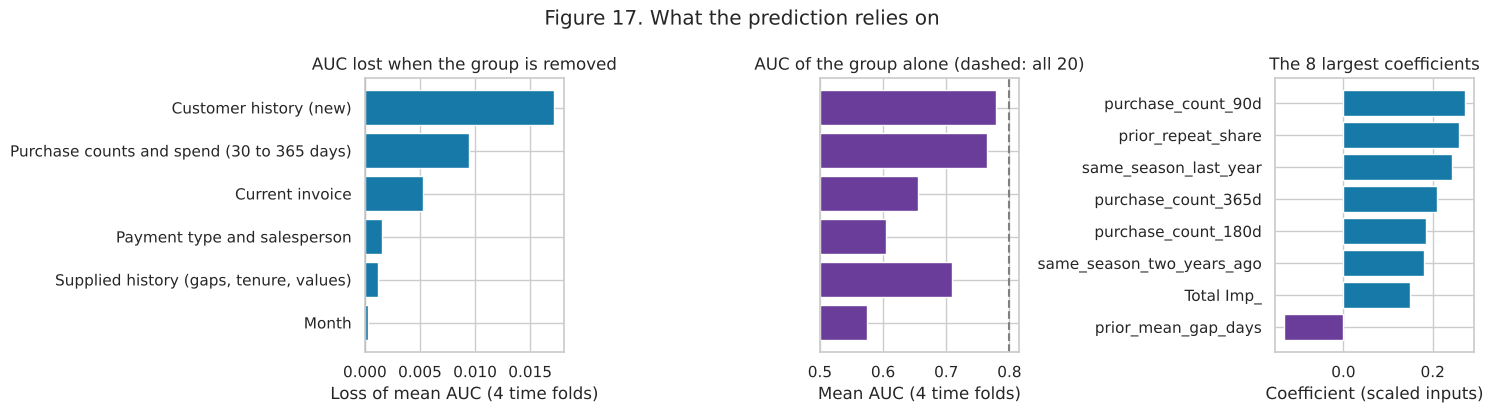

All 20 variables: AUC 0.8001, F1 0.7533
Customer history (new) (3): AUC lost 0.0172 (in 4 of 4 folds), F1 without it 0.7467, alone: AUC 0.7784, F1 0.7539
Purchase counts and spend (30 to 365 days) (4): AUC lost 0.0094 (in 2 of 4 folds), F1 without it 0.7572, alone: AUC 0.7645, F1 0.7331
Current invoice (6): AUC lost 0.0053 (in 3 of 4 folds), F1 without it 0.7488, alone: AUC 0.6559, F1 0.6926
Payment type and salesperson (2): AUC lost 0.0015 (in 3 of 4 folds), F1 without it 0.7520, alone: AUC 0.6044, F1 0.7025
Supplied history (gaps, tenure, values) (4): AUC lost 0.0012 (in 4 of 4 folds), F1 without it 0.7556, alone: AUC 0.7086, F1 0.7258
Month (1): AUC lost 0.0003 (in 2 of 4 folds), F1 without it 0.7546, alone: AUC 0.5739, F1 0.7116
Largest coefficients: {'purchase_count_90d': 0.27, 'prior_repeat_share': 0.26, 'same_season_last_year': 0.24, 'purchase_count_365d': 0.21, 'purchase_count_180d': 0.19, 'same_season_two_years_ago': 0.18, 'Total Imp_': 0.15, 'prior_mean_gap_days': -0.13}
Coef

In [4]:
# AUC lost without a group, AUC of the group alone, and the largest coefficients of the final model
encoded_names = holdout_pipeline["prep"].get_feature_names_out()
coefficients = pd.Series(holdout_pipeline["model"].coef_[0], index=encoded_names)
numeric_coefficients = coefficients[coefficients.index.isin(FINAL_NUMERIC + FINAL_FLAGS)]
strongest = numeric_coefficients.reindex(numeric_coefficients.abs().sort_values().index).tail(8)
month_coefficients = coefficients[coefficients.index.str.startswith("month_")]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
order = ablation.index[::-1]
axes[0].barh(order, ablation.loc[order, "AUC lost"], color=PLOT_BLUE)
axes[0].axvline(0, color="grey")
axes[0].set(title="AUC lost when the group is removed", xlabel="Loss of mean AUC (4 time folds)")
axes[1].barh(order, ablation.loc[order, "AUC alone"] - 0.5, left=0.5, color=PLOT_PURPLE)
axes[1].axvline(full_scores["test_auc"].mean(), color="grey", linestyle="--")
axes[1].set(title=f"AUC of the group alone (dashed: all {len(final_variables)})",
            xlabel="Mean AUC (4 time folds)", yticklabels=[])
axes[2].barh(strongest.index, strongest, color=np.where(strongest > 0, PLOT_BLUE, PLOT_PURPLE))
axes[2].set(title="The 8 largest coefficients", xlabel="Coefficient (scaled inputs)")
fig.suptitle("Figure 17. What the prediction relies on")
plt.tight_layout()
plt.show()
print(f"All {len(final_variables)} variables: AUC {full_scores['test_auc'].mean():.4f}, "
      f"F1 {full_scores['test_f1'].mean():.4f}")
for name, group_scores in ablation.iterrows():
    print(f"{name} ({group_scores['Variables']:.0f}): AUC lost {group_scores['AUC lost']:.4f} "
          f"(in {group_scores['Folds with a loss']:.0f} of 4 folds), F1 without it {group_scores['F1 without']:.4f}, "
          f"alone: AUC {group_scores['AUC alone']:.4f}, F1 {group_scores['F1 alone']:.4f}")
print("Largest coefficients:", strongest[::-1].round(2).to_dict())
print(f"Coefficients of the 12 months: {month_coefficients.min():.2f} ({month_coefficients.idxmin()}) "
      f"to {month_coefficients.max():.2f} ({month_coefficients.idxmax()})")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results and discussion</b></p>
<ul>
  <li><b>Customer history</b> is the most valuable group: without its 3 variables the AUC falls by 0.0172 (in 4 of 4 folds); alone they reach an F1 of 0.7539, as high as the full set (0.7533)</li>
  <li><b>Purchase counts and spend</b> come second (AUC loss 0.0094). The <b>current invoice</b> is weak alone (AUC 0.656) but still costs 0.0053 AUC in 3 of 4 folds, so discount and invoice size add something the history lacks</li>
  <li>Payment type, salesperson, the supplied history and the month each cost at most 0.0015 AUC</li>
  <li>The coefficients agree: the six largest all describe the purchase rhythm (Figure 17, right), and the 12 month coefficients only range from -0.09 to 0.08</li>
</ul>

</div>

<h3>Objective 2: for which customers is the prediction unreliable?</h3>

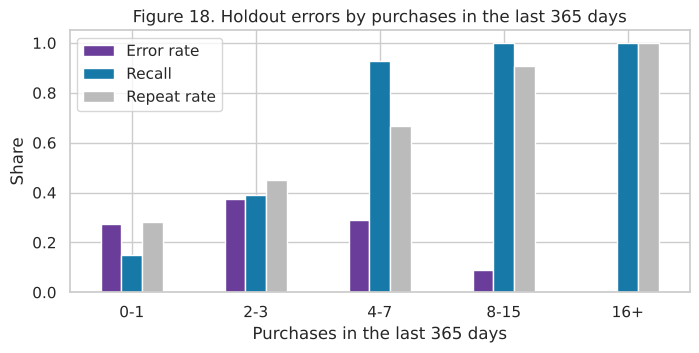

0-1 purchases: 191 rows, repeat rate 0.283, predicted 0.073, recall 0.148, error rate 0.272
2-3 purchases: 281 rows, repeat rate 0.448, predicted 0.274, recall 0.389, error rate 0.374
4-7 purchases: 359 rows, repeat rate 0.666, predicted 0.861, recall 0.929, error rate 0.290
8-15 purchases: 165 rows, repeat rate 0.909, predicted 1.000, recall 1.000, error rate 0.091
16+ purchases: 82 rows, repeat rate 1.000, predicted 1.000, recall 1.000, error rate 0.000


In [5]:
# scores of the final model for the holdout rows of one segment
def segment_scores(mask):
    truth, predicted = y_holdout[mask], holdout_prediction[mask]
    return {"Rows": int(mask.sum()), "Repeat rate": truth.mean(),
            "Predicted repeat rate": predicted.mean(),
            "Precision": precision_score(truth, predicted, zero_division=0),
            "Recall": recall_score(truth, predicted, zero_division=0),
            "F1": f1_score(truth, predicted, zero_division=0),
            "Error rate": (truth != predicted).mean()}


frequency_labels = ["0-1", "2-3", "4-7", "8-15", "16+"]
frequency = pd.cut(X_holdout["purchase_count_365d"], [-1, 1, 3, 7, 15, 500], labels=frequency_labels)
by_frequency = pd.DataFrame({segment: segment_scores((frequency == segment).to_numpy())
                             for segment in frequency.cat.categories}).T

ax = by_frequency[["Error rate", "Recall", "Repeat rate"]].plot(
    kind="bar", rot=0, figsize=(8, 3.4), color=[PLOT_PURPLE, PLOT_BLUE, "#BBBBBB"])
ax.set(title="Figure 18. Holdout errors by purchases in the last 365 days",
       xlabel="Purchases in the last 365 days", ylabel="Share")
plt.show()
for segment, segment_row in by_frequency.iterrows():
    print(f"{segment} purchases: {segment_row['Rows']:.0f} rows, repeat rate {segment_row['Repeat rate']:.3f}, "
          f"predicted {segment_row['Predicted repeat rate']:.3f}, recall {segment_row['Recall']:.3f}, "
          f"error rate {segment_row['Error rate']:.3f}")

In [6]:
# holdout scores of known customers, new customers and first purchases
is_known = X_holdout["customer_id"].isin(X_dev["customer_id"]).to_numpy()
is_first = (X_holdout["prior_purchase_count"] == 0).to_numpy()
segments = {"Customers known from the development part": is_known, "New customers": ~is_known,
            "First purchases": is_first}
for name, mask in segments.items():
    customer_scores = segment_scores(mask)
    print(f"{name}: {customer_scores['Rows']} rows, repeat rate {customer_scores['Repeat rate']:.3f}, "
          f"F1 {customer_scores['F1']:.3f}, error rate {customer_scores['Error rate']:.3f}")
print(f"All holdout rows: error rate {(y_holdout != holdout_prediction).mean():.3f}")

Customers known from the development part: 945 rows, repeat rate 0.613, F1 0.796, error rate 0.251
New customers: 133 rows, repeat rate 0.541, F1 0.711, error rate 0.293
First purchases: 35 rows, repeat rate 0.257, F1 0.000, error rate 0.257
All holdout rows: error rate 0.256


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results and discussion</b></p>
<ul>
  <li>25.6% of the holdout predictions are wrong, but not evenly (Figure 18)</li>
  <li><b>8 or more purchases a year</b>: at most 9.1% errors; the model always predicts a repeat</li>
  <li><b>2 to 3 purchases a year</b>: 37.4% errors; these customers return in 44.8% of cases, and the model finds 38.9% of them</li>
  <li><b>0 to 1 purchases</b>: the model rarely predicts a repeat (7.3%) and finds 14.8% of the repeats</li>
  <li><b>New customers</b>: F1 0.711 against 0.796 for known ones; <b>first purchases</b> (35): F1 0, because without history the model cannot find the 25.7% who return</li>
  <li>--> trust the yes/no only for frequent buyers; for the others the probability is the more honest output (Objective 3)</li>
</ul>

</div>

<h3>Objective 3: are the probabilities right, and can they rank customers?</h3>

Log loss of always predicting the development repeat rate (0.549): 0.6774
Final model: log loss 0.5197, F1 at 0.5 0.7874, mean probability 0.577 (observed rate 0.604)
Calibrated (sigmoid): log loss 0.5127, F1 at 0.5 0.7811, mean probability 0.584 (observed rate 0.604)
Calibrated (isotonic): log loss 0.5449, F1 at 0.5 0.7781, mean probability 0.584 (observed rate 0.604)


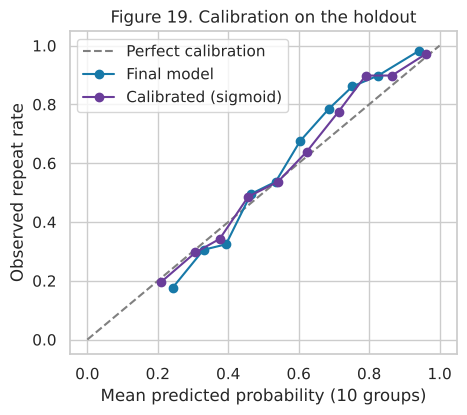

In [7]:
# log loss of the model, of the repeat rate alone, and of the model calibrated on the time folds
base_rate = np.full(len(y_holdout), y_dev.mean())
probabilities = {"Final model": holdout_probability}
for method in tqdm(["sigmoid", "isotonic"], desc="calibration methods", leave=True, position=0):
    calibrated = CalibratedClassifierCV(build_final_pipeline(), method=method, cv=inner_folds).fit(X_dev, y_dev)
    probabilities[f"Calibrated ({method})"] = calibrated.predict_proba(X_holdout)[:, 1]
print(f"Log loss of always predicting the development repeat rate ({y_dev.mean():.3f}): "
      f"{log_loss(y_holdout, base_rate):.4f}")
for name, probability in probabilities.items():
    print(f"{name}: log loss {log_loss(y_holdout, probability):.4f}, "
          f"F1 at {THRESHOLD} {f1_score(y_holdout, probability >= THRESHOLD):.4f}, "
          f"mean probability {probability.mean():.3f} (observed rate {y_holdout.mean():.3f})")

# predicted against observed repeat rate in 10 groups of equal size
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Perfect calibration")
for (name, probability), color in zip(list(probabilities.items())[:2], [PLOT_BLUE, PLOT_PURPLE]):
    groups = pd.qcut(probability, 10, labels=False, duplicates="drop")
    reliability = pd.DataFrame({"predicted": probability, "observed": y_holdout.to_numpy()}).groupby(groups).mean()
    ax.plot(reliability["predicted"], reliability["observed"], marker="o", color=color, label=name)
ax.set(title="Figure 19. Calibration on the holdout",
       xlabel="Mean predicted probability (10 groups)", ylabel="Observed repeat rate")
ax.legend()
plt.show()

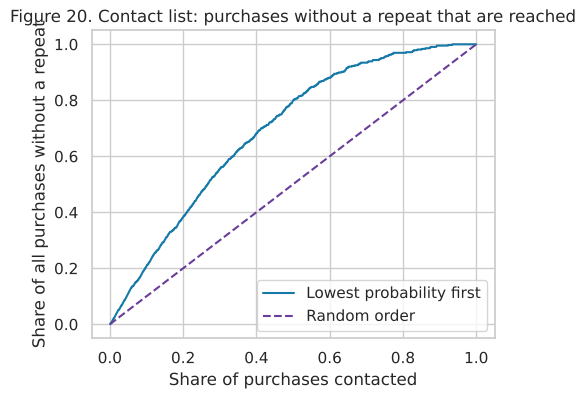

Lowest 10%: 82.2% of them do not repeat, 20.6% of all purchases without a repeat are reached
Lowest 30%: 73.4% of them do not repeat, 55.5% of all purchases without a repeat are reached
Lowest 50%: 63.3% of them do not repeat, 79.9% of all purchases without a repeat are reached
Purchases without a repeat in the whole holdout: 39.6%


In [8]:
# contact list: purchases sorted from the lowest to the highest probability of a repeat
ranked = pd.DataFrame({"probability": holdout_probability, "no_repeat": 1 - y_holdout.to_numpy()})
ranked = ranked.sort_values("probability").reset_index(drop=True)
share_contacted = (ranked.index + 1) / len(ranked)
share_reached = ranked["no_repeat"].cumsum() / ranked["no_repeat"].sum()

fig, ax = plt.subplots(figsize=(5.2, 4))
ax.plot(share_contacted, share_reached, color=PLOT_BLUE, label="Lowest probability first")
ax.plot([0, 1], [0, 1], color=PLOT_PURPLE, linestyle="--", label="Random order")
ax.set(title="Figure 20. Contact list: purchases without a repeat that are reached",
       xlabel="Share of purchases contacted", ylabel="Share of all purchases without a repeat")
ax.legend()
plt.show()
for share in [0.1, 0.3, 0.5]:
    contacted = ranked.iloc[:int(share * len(ranked))]
    reached = contacted["no_repeat"].sum() / ranked["no_repeat"].sum()
    print(f"Lowest {share:.0%}: {contacted['no_repeat'].mean():.1%} of them do not repeat, "
          f"{reached:.1%} of all purchases without a repeat are reached")
print(f"Purchases without a repeat in the whole holdout: {ranked['no_repeat'].mean():.1%}")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results and discussion</b></p>
<ul>
  <li><b>Probabilities</b>: log loss 0.520 against 0.677 for always predicting the development repeat rate --> they carry information. They are slightly too low in the newest period (mean 0.577 against an observed 0.604), because it has more repeats than the development part (0.549; Figure 19)</li>
  <li><b>Calibration</b> on the time folds: sigmoid lowers the log loss a little (0.513) but also the F1 (0.781 against 0.787); isotonic is worse (0.545), so the more flexible calibration does not pay off --> the final model stays uncalibrated, because the F1 decides</li>
  <li><b>Contact list</b>: the 30% of purchases with the lowest probability contain 55.5% of all purchases without a repeat, and 73.4% of them are such purchases (39.6% in the whole holdout; Figure 20) --> the company can choose the size of a campaign from the probability</li>
</ul>

</div>

<h3>Objective 4: a tool that explains one prediction</h3>

In [9]:
# probability of a repeat purchase for one row and the variables that move it most
def explain_purchase(purchase, pipeline=holdout_pipeline, n_reasons=5):
    one_row = purchase.to_frame().T.infer_objects()
    encoded = pipeline["prep"].transform(one_row)[0]
    variables = [prep.source_variable(name, FINAL_CATEGORICAL)
                 for name in pipeline["prep"].get_feature_names_out()]
    contributions = pd.Series(encoded * pipeline["model"].coef_[0], index=variables)
    contributions = contributions.groupby(level=0).sum()
    by_size = contributions.abs().sort_values(ascending=False).index
    reasons = contributions.reindex(by_size).head(n_reasons)
    return pipeline.predict_proba(one_row)[0, 1], reasons


for position in [int(np.argmax(holdout_probability)), int(np.argmin(holdout_probability))]:
    purchase = X_holdout.iloc[position]
    probability, reasons = explain_purchase(purchase)
    print(f"Purchase ID {purchase['ID']}: probability of a repeat purchase {probability:.2f}, "
          f"prediction {int(probability >= THRESHOLD)}, what happened: {y_holdout.iloc[position]}")
    for variable, effect in reasons.items():
        direction = "more likely to repeat" if effect > 0 else "less likely to repeat"
        print(f"  {variable} = {purchase[variable]}: {effect:+.2f} on the log-odds ({direction})")

Purchase ID 10000998: probability of a repeat purchase 0.98, prediction 1, what happened: 1
  same_season_two_years_ago = 12: +0.58 on the log-odds (more likely to repeat)
  purchase_count_90d = 8.0: +0.57 on the log-odds (more likely to repeat)
  same_season_last_year = 8: +0.56 on the log-odds (more likely to repeat)
  purchase_count_365d = 32.0: +0.43 on the log-odds (more likely to repeat)
  purchase_count_180d = 15.0: +0.37 on the log-odds (more likely to repeat)
Purchase ID 10003595: probability of a repeat purchase 0.12, prediction 0, what happened: 1
  prior_repeat_share = 0.0: -0.38 on the log-odds (less likely to repeat)
  prior_mean_gap_days = 2524.0: -0.33 on the log-odds (less likely to repeat)
  purchase_count_365d = 0.0: -0.32 on the log-odds (less likely to repeat)
  purchase_count_90d = 0.0: -0.23 on the log-odds (less likely to repeat)
  purchase_count_180d = 0.0: -0.23 on the log-odds (less likely to repeat)


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results and discussion</b></p>
<ul>
  <li><b>explain_purchase</b> returns the probability and the five variables that move it most (coefficient times scaled value, summed over the one-hot columns of a category). This only works because the final model is linear</li>
  <li>Purchase 10000998 gets 0.98: 12 and 8 purchases in the same season of the last two years. Purchase 10003595 gets 0.12 (no earlier repeat, mean gap of 2,524 days), but the customer came back, an occasional buyer from Objective 2</li>
</ul>

</div>

<h3>Key takeaways</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Drivers</b>: the purchase rhythm drives the prediction; three history variables alone match the full set (F1 0.754 against 0.753)</li>
  <li><b>Errors</b>: reliable for frequent buyers (at most 9% errors), unreliable for occasional buyers (37%) and blind for first purchases</li>
  <li><b>Probabilities</b>: the ranking is useful even where the yes/no is not; calibration adds little</li>
  <li><b>Limits</b>: the holdout is one period of 1,078 purchases, and some segments are small (35 first purchases)</li>
</ul>

</div>

<a id="deployment"></a>

<h1>V. Deployment</h1>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>This is the <b>first and only use of test.csv</b>: the finished model is applied to it. The function starts from the raw files and runs every step in the same order: the row rules of Notebook 1 (prepare_purchases), the pipeline chosen in Notebook 2 fitted on all training rows, and the threshold. Nothing is fitted on test.csv, and no rule was derived from it.</p>

</div>

In [10]:
# raw train.csv and test.csv to one prediction for every row of test.csv
def predict_repeat_purchases(raw_folder="../data/raw"):
    raw_train = pd.read_csv(f"{raw_folder}/train.csv")
    raw_test = pd.read_csv(f"{raw_folder}/test.csv")
    prepared_train, prepared_test = prep.prepare_purchases(raw_train, new_purchases=raw_test)
    pipeline = build_final_pipeline().fit(prepared_train, prepared_train[TARGET])
    probability = pipeline.predict_proba(prepared_test)[:, 1]
    submission = pd.DataFrame({"ID": prepared_test["ID"],
                               TARGET: (probability >= THRESHOLD).astype(int)})
    return submission, probability, prepared_train, prepared_test


submission, test_probability, prepared_train, prepared_test = predict_repeat_purchases()
submission.head()

,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,0
3,10000020,0
4,10000025,1


In [11]:
# checks of the predictions against sample_submission.csv
sample_submission = pd.read_csv("../data/raw/sample_submission.csv")
test_matrix = holdout_pipeline["prep"].transform(prepared_test)

checks = {
    "One prediction for every row of sample_submission.csv": len(submission) == len(sample_submission),
    "IDs and their order equal sample_submission.csv": submission["ID"].equals(sample_submission["ID"]),
    "Column names equal sample_submission.csv":
        list(submission.columns) == list(sample_submission.columns),
    "Predictions are only 0 or 1": bool(submission[TARGET].isin([0, 1]).all()),
    "Training rows are prepared exactly as in Notebook 1": prepared_train.equals(train),
    "No missing value after the pre-processing": not np.isnan(test_matrix).any(),
}
for check, passed in checks.items():
    print(f"{check}: {passed}")

One prediction for every row of sample_submission.csv: True
IDs and their order equal sample_submission.csv: True
Column names equal sample_submission.csv: True
Predictions are only 0 or 1: True
Training rows are prepared exactly as in Notebook 1: True
No missing value after the pre-processing: True


In [12]:
Path("../results").mkdir(exist_ok=True)
submission.to_csv("../results/Group30_submission.csv", index=False)
print(f"Saved results/Group30_submission.csv with {len(submission)} predictions")
print(f"Share of predicted repeats in test.csv: {submission[TARGET].mean():.3f} "
      f"(holdout: {holdout_prediction.mean():.3f}), mean probability: {test_probability.mean():.3f}")

# a first look at test.csv, after the predictions are made
days_between = (pd.to_datetime(prepared_test["purchase_date"]).min()
                - pd.to_datetime(prepared_train["purchase_date"]).max()).days
print(f"test.csv: {prepared_test['purchase_date'].min()} to {prepared_test['purchase_date'].max()}, "
      f"it starts {days_between} days after the end of train.csv")
print(f"First purchases in test.csv: {(prepared_test['prior_purchase_count'] == 0).mean():.1%}, "
      f"in train: {(train['prior_purchase_count'] == 0).mean():.1%}")

Saved results/Group30_submission.csv with 986 predictions
Share of predicted repeats in test.csv: 0.665 (holdout: 0.600), mean probability: 0.611
test.csv: 2025-05-24 to 2026-10-06, it starts 98 days after the end of train.csv
First purchases in test.csv: 2.2%, in train: 9.3%


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Result</b></p>
<ul>
  <li>One prediction for each of the 986 rows; all six checks pass, and adding test.csv does not change the training rows</li>
  <li>The function handles new data: impossible values are repaired by rule, gaps get the training median or "missing", new levels join the rare levels, and no row is dropped</li>
  <li>The model predicts a repeat for 66.5% of the test purchases (holdout 60.0%); plausible, as only 2.2% of the test rows are first purchases (9.3% in train)</li>
  <li><b>Limitation</b>: test.csv starts 98 days after train.csv ends; purchases from those days are missing, so some histories are incomplete</li>
  <li><b>Submission</b>: results/Group30_submission.csv is the file we select on Kaggle. It scores 0.80314 on the public leaderboard (the version with clientes.csv: 0.79892), above the 0.787 of the holdout, as expected from the higher share of predicted repeats in test.csv. It was chosen on the time folds, never by the leaderboard</li>
</ul>

</div>